# RDST vs one-class anomaly detection – processes A and B

**RDST** (Random Dilated Shapelet Transform + sensor spread + ridge) is the **supervised** model trained by the team on the `feature/rdst` branch (`03_rdst_spread_seed0.ipynb`, models in `models/`). It learns from accepted **and** rejected batches. The detectors in `anomaly_detection.ipynb` learn from **accepted batches only**. This notebook:

1. **Compares** them on exactly the same held-out batches (the RDST test splits: process A 30 %, process B 50 %). For a fair comparison the one-class detectors are fitted on the accepted batches of the RDST *training* split only.
2. **Explains RDST over time.** Grad-CAM needs a neural network, so it cannot be applied to RDST. We use **occlusion** instead, which works for any model: each 5 % slice of a batch is replaced by the normal trajectory (median of the accepted training batches) and we measure how much RDST's "rejected" score drops. A large drop = that part of the batch made RDST say "rejected". Same sanity check as in `gradcam_anomaly.ipynb`: for process B the evidence should sit in the aeration-drop window t = 500–1250.

**Not done:** RDST features inside a one-class detector. RDST picks its shapelets using the labels; fitted on accepted batches only it would give 30,000 random pattern features for 35–85 batches, so a max-over-features score would mostly reflect chance.

**Requirements:** the saved RDST models and the RDST code are read directly from the `feature/rdst` branch with `git show` (nothing is copied into this branch, nothing on that branch is changed). Loading them needs `aeon` (as the RDST notebooks do) – run this notebook in an environment with `aeon` installed.

## 0. Setup: RDST code and models from the `feature/rdst` branch

In [1]:
import json, subprocess, io, numpy as np, pandas as pd, matplotlib.pyplot as plt, cloudpickle, nbformat
from pathlib import Path
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import RobustScaler
%matplotlib inline
plt.rcParams.update({"figure.dpi":110,"axes.spines.top":False,"axes.spines.right":False,"axes.grid":True,"grid.alpha":.25,
                     "axes.titleweight":"bold","axes.titlesize":10,"axes.labelsize":9,"legend.frameon":False,"legend.fontsize":9,"axes.formatter.useoffset":False})
ACC,REJ,TEST,INK,WIN_COL="#8a8f98","#d62728","#2a78d6","#333333","#f0e442"
BRANCH="origin/feature/rdst"
def git_bytes(path):
    """read a file from the RDST branch without checking it out"""
    return subprocess.run(["git","show",f"{BRANCH}:{path}"],capture_output=True,check=True).stdout

# RDST helper code (load_batches, fixed_length, spread, inputs, Model) exactly as in the team's notebook
rdst_nb=nbformat.reads(git_bytes("03_rdst_spread_seed0.ipynb").decode(),as_version=4)
for i in (1,2): exec(rdst_nb.cells[i].source)
MODELS={p:cloudpickle.loads(git_bytes(f"models/rdst_process_{p}_seed0.pkl")) for p in ("A","B")}
META={p:json.loads(git_bytes(f"models/rdst_process_{p}_seed0.json")) for p in ("A","B")}

def rdst_score(m,series,spread_block):
    """continuous RDST output (ridge decision value; > 0 = rejected) – same steps as Model.predict"""
    shapes=m._clean(m.rdst.transform(m._scale(series)))
    return m.ridge.decision_function(m._join(shapes,spread_block,m.weight))

B={}; LAB={}
for p in ("A","B"):
    folder=DATA_DIR/f"process {p}"/"calibration data"
    B[p]=load_batches(folder/"calibration_data.csv")
    LAB[p]=pd.read_csv(folder/"calibration_labels.csv").set_index("batch_id").label
    tr,te=META[p]["train_ids"],META[p]["test_ids"]
    print(f"process {p}: RDST train {len(tr)} batches ({(LAB[p][tr]=='rejected').sum()} rejected) | test {len(te)} batches ({(LAB[p][te]=='rejected').sum()} rejected)")

/home/renku/work/input-data/Project 2 - BRPMM


process A: RDST train 112 batches (28 rejected) | test 49 batches (12 rejected)


process B: RDST train 20 batches (3 rejected) | test 20 batches (2 rejected)


## 1. Same test batches: RDST vs one-class detectors
- **RDST:** the saved model, predicting its own test split (as in `models/rdst_process_*_seed0.json`).
- **Robust deviation score** and **Isolation Forest:** as in `anomaly_detection.ipynb` (per-batch median, std, RSD, + range for B), but fitted on the **accepted batches of the RDST training split only**; threshold = 95th percentile of their leave-one-batch-out scores; then applied to the RDST test split.

In [2]:
def features(batches,ids,with_range):
    rows={}
    for b in ids:
        a=batches[b]; mu=a.mean(0); sd=a.std(0,ddof=1)
        f=np.r_[np.median(a,0),sd,np.where(np.abs(mu)>0,sd/np.abs(np.where(mu==0,1,mu)),np.nan)]
        if with_range: f=np.r_[f,a.max(0)-a.min(0)]
        rows[b]=f
    return pd.DataFrame(rows).T

def fit_robust(Fa):
    med=Fa.median(); iqr=Fa.quantile(.75)-Fa.quantile(.25); scale=iqr.where(iqr>0,Fa.std()); scale=scale[scale>0]
    return lambda X: ((X[scale.index]-med[scale.index]).abs()/scale).max(axis=1)
def fit_iforest(Fa):
    sc=RobustScaler().fit(Fa); iso=IsolationForest(n_estimators=300,random_state=0).fit(np.clip(sc.transform(Fa),-20,20))
    return lambda X: pd.Series(-iso.score_samples(np.clip(sc.transform(X[Fa.columns]),-20,20)),index=X.index)

rows=[]; PRED={}
for p in ("A","B"):
    tr,te=META[p]["train_ids"],META[p]["test_ids"]; y_te=(LAB[p][te]=="rejected").values
    F=features(B[p],tr+te,p=="B"); F=F.loc[:,F.notna().all() & (F.loc[tr].std()>0)]
    acc_tr=[b for b in tr if LAB[p][b]=="accepted"]
    s,sp=inputs(B[p],te); PRED[(p,"RDST (supervised)")]=pd.Series(MODELS[p].predict(s,sp)==1,index=te)
    for name,fit in (("Robust deviation score (one-class)",fit_robust),("Isolation Forest (one-class)",fit_iforest)):
        loo=[fit(F.loc[[a for a in acc_tr if a!=b]])(F.loc[[b]]).iloc[0] for b in acc_tr]
        thr=np.percentile(loo,95); PRED[(p,name)]=fit(F.loc[acc_tr])(F.loc[te])>thr
    for name in ("RDST (supervised)","Robust deviation score (one-class)","Isolation Forest (one-class)"):
        f=PRED[(p,name)].reindex(te).values
        rows.append({"process":p,"model":name,"trained on":"accepted + rejected" if "RDST" in name else "accepted only",
                     "rejected caught":f"{(f&y_te).sum()}/{y_te.sum()}","false alarms":f"{(f&~y_te).sum()}/{(~y_te).sum()}",
                     "recall":(f&y_te).sum()/y_te.sum(),"false-alarm rate":(f&~y_te).sum()/(~y_te).sum()})
CMP=pd.DataFrame(rows); display(CMP.style.format({"recall":"{:.0%}","false-alarm rate":"{:.0%}"}).hide(axis="index"))

process,model,trained on,rejected caught,false alarms,recall,false-alarm rate
A,RDST (supervised),accepted + rejected,10/12,2/37,83%,5%
A,Robust deviation score (one-class),accepted only,4/12,4/37,33%,11%
A,Isolation Forest (one-class),accepted only,0/12,0/37,0%,0%
B,RDST (supervised),accepted + rejected,2/2,0/18,100%,0%
B,Robust deviation score (one-class),accepted only,2/2,1/18,100%,6%
B,Isolation Forest (one-class),accepted only,0/2,4/18,0%,22%


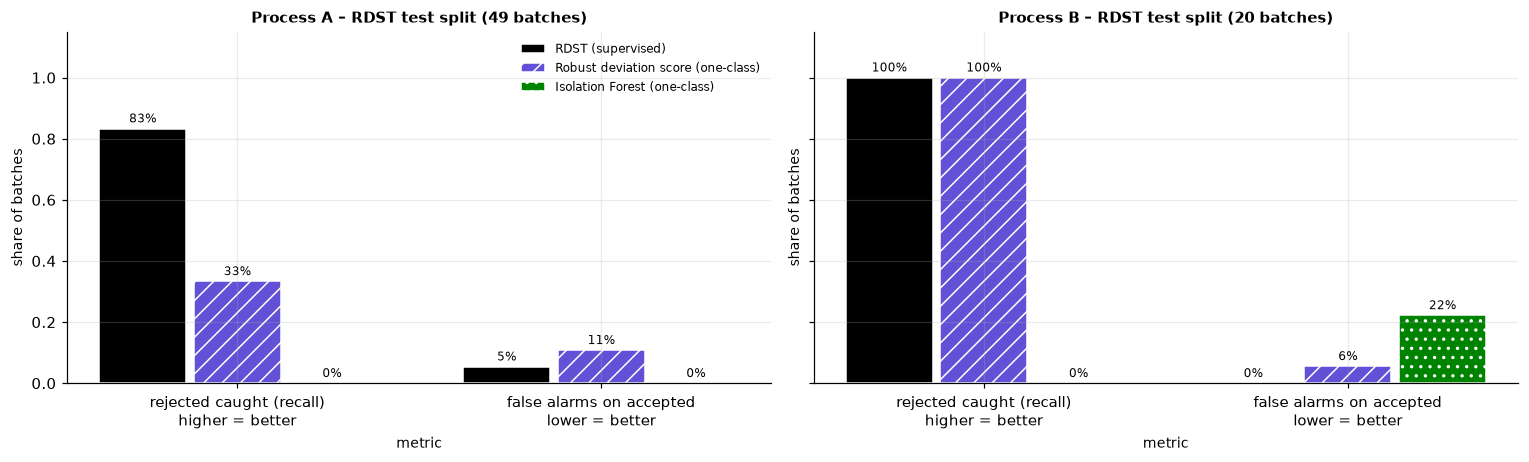

In [3]:
fig,axs=plt.subplots(1,2,figsize=(14,4.3),sharey=True)
names=["RDST (supervised)","Robust deviation score (one-class)","Isolation Forest (one-class)"]; cols=["#000000","#6250d6","#008300"]; hatch=[None,"//",".."]
for ax,p in zip(axs,("A","B")):
    d=CMP[CMP.process==p].set_index("model").loc[names]; x=np.arange(2); w=.26
    for k,(n,c,h) in enumerate(zip(names,cols,hatch)):
        vals=[d.loc[n,"recall"],d.loc[n,"false-alarm rate"]]
        bars=ax.bar(x+(k-1)*w,vals,w*.92,color=c,hatch=h,edgecolor="white",label=n)
        for b_,v in zip(bars,vals): ax.text(b_.get_x()+b_.get_width()/2,v+.02,f"{v:.0%}",ha="center",fontsize=8)
    ax.set_xticks(x,["rejected caught (recall)\nhigher = better","false alarms on accepted\nlower = better"])
    ax.set(title=f"Process {p} – RDST test split ({len(META[p]['test_ids'])} batches)",xlabel="metric",ylabel="share of batches",ylim=(0,1.15))
axs[0].legend(loc="upper right",fontsize=8); plt.tight_layout(); plt.show()

## 2. Explaining RDST over time (occlusion)
For a batch, RDST gives a score (> 0 = rejected). We cut the batch into **20 slices** (5 % of the run each). A window of **4 neighbouring slices (20 % of the run)** slides over the batch one slice at a time. Inside the window the raw data are replaced by the **normal trajectory**: the per-timestep median of the accepted *training* batches (process A: compared on normalised time), shifted to the batch's own level so the replacement does not create an artificial jump. Both RDST inputs (shapelet series and spread block) are recomputed and the batch re-scored. **Importance of a slice = the average drop of the "rejected" score over the windows that hide it** (negative drops set to 0), scaled to 0–1 within the batch.

*Why a 20 % window:* hiding a single 5 % slice never changes RDST's verdict for process B, because the aeration drop spans three slices – the remaining part still shows the drop.

Batches explained: all rejected batches of the RDST test split, plus one accepted test batch for reference. For process B we additionally explain the 3 rejected *training* batches (the test split has only 2), marked as such.

In [4]:
NW=20; WIDTH=4          # 20 slices of 5 %; each occlusion hides 4 neighbouring slices (20 % of the run), sliding 1 slice at a time
def reference(p,a):
    """normal trajectory for batch a: median accepted-training trajectory (normalised time), shifted to the batch's own level per variable"""
    n=len(a); acc_tr=[b for b in META[p]["train_ids"] if LAB[p][b]=="accepted"]; g=np.linspace(0,1,n)
    R=np.median(np.stack([np.stack([np.interp(g,np.linspace(0,1,len(B[p][b])),B[p][b][:,j]) for j in range(a.shape[1])],1) for b in acc_tr]),0)
    return R+(np.median(a,0)-np.median(R,0))       # same level as the batch -> no artificial jump at the window edges

def occlusion(p,b):
    a=B[p][b]; n=len(a); ref=reference(p,a); edges=np.linspace(0,n,NW+1).astype(int)
    wins=[(k,k+WIDTH) for k in range(NW-WIDTH+1)]
    variants=[a]+[np.vstack([a[:edges[k0]],ref[edges[k0]:edges[k1]],a[edges[k1]:]]) for k0,k1 in wins]
    tmp={f"v{k}":v for k,v in enumerate(variants)}; s,sp=inputs(tmp,list(tmp))
    sc=rdst_score(MODELS[p],s,sp); drop=np.clip(sc[0]-sc[1:],0,None)
    imp=np.zeros(NW); cnt=np.zeros(NW)
    for (k0,k1),d_ in zip(wins,drop): imp[k0:k1]+=d_; cnt[k0:k1]+=1
    imp/=cnt                                         # importance of a slice = mean score drop of the windows that hide it
    return dict(score=sc[0],imp=imp/imp.max() if imp.max()>0 else imp,max_drop=drop.max(),edges=edges/n)

EXPL={}
for p in ("A","B"):
    te=META[p]["test_ids"]; rej=[b for b in te if LAB[p][b]=="rejected"]; acc_ref=[b for b in te if LAB[p][b]=="accepted"][0]
    extra=[b for b in META[p]["train_ids"] if LAB[p][b]=="rejected"] if p=="B" else []
    for b in rej+extra+[acc_ref]: EXPL[(p,b)]=occlusion(p,b)
    print(f"process {p}: explained {len(rej)} rejected test batches"+(f" + {len(extra)} rejected training batches" if extra else "")+f" + reference {acc_ref}")

process A: explained 12 rejected test batches + reference A_005


process B: explained 2 rejected test batches + 3 rejected training batches + reference B_005


### 2.1 Process B – where RDST sees "rejected"
Each block: the batch's `aeration_rate` (red = rejected, blue = accepted reference) against the accepted training batches (grey), with the known aeration-drop window shaded yellow; below it, the **occlusion importance** strip (darker = removing that slice lowers RDST's "rejected" score the most).

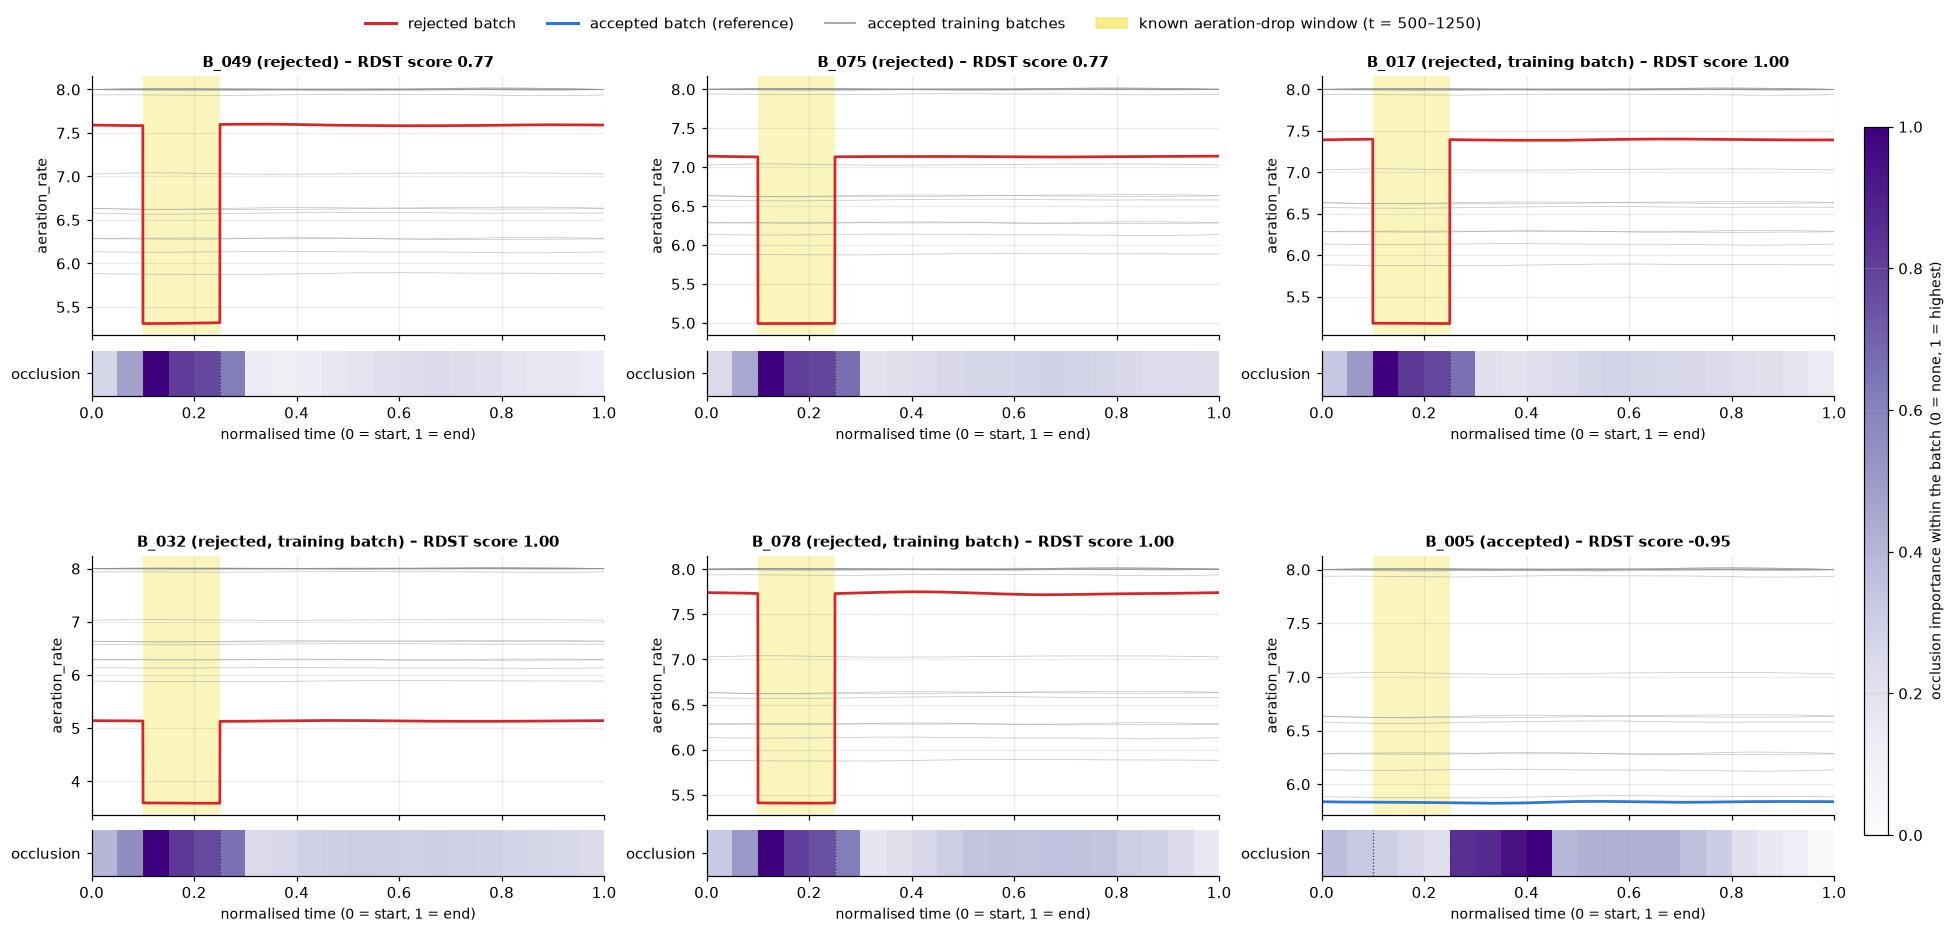

rejected B batches whose most important slice lies inside t = 500–1250: 5/5
largest score drop per batch (RDST score > 0 = rejected): B_049: score 0.77, max drop 1.81, B_075: score 0.77, max drop 1.95, B_017: score 1.00, max drop 1.92, B_032: score 1.00, max drop 1.81, B_078: score 1.00, max drop 1.64
rejected B batches: share of occlusion importance inside t = 500–1250 = 35 % on average (per batch: B_049 40 %, B_075 35 %, B_017 36 %, B_032 32 %, B_078 32 %); chance level = 15 %


In [5]:
from matplotlib.gridspec import GridSpecFromSubplotSpec
def block(fig,spec,p,b,var,window=None,note=""):
    e=EXPL[(p,b)]; a=B[p][b]; sens=pd.read_csv(DATA_DIR/f"process {p}"/"calibration data"/"calibration_data.csv",nrows=1).columns.drop("batch_id")
    j=list(sens).index(var); tn=lambda x: np.linspace(0,1,len(x))
    gs=GridSpecFromSubplotSpec(2,1,subplot_spec=spec,height_ratios=[4,.7],hspace=.1)
    ax=fig.add_subplot(gs[0]); s_=fig.add_subplot(gs[1],sharex=ax)
    if window: ax.axvspan(*window,color=WIN_COL,alpha=.35,lw=0)
    for o in META[p]["train_ids"]:
        if LAB[p][o]=="accepted": ax.plot(tn(B[p][o]),B[p][o][:,j],color=ACC,lw=.5,alpha=.5)
    ax.plot(tn(a),a[:,j],color=REJ if LAB[p][b]=="rejected" else TEST,lw=1.8)
    ax.set_title(f"{b} ({LAB[p][b]}{note}) – RDST score {e['score']:.2f}"); ax.set_ylabel(var); plt.setp(ax.get_xticklabels(),visible=False)
    s_.imshow(e["imp"][None,:],aspect="auto",cmap="Purples",vmin=0,vmax=1,extent=(0,1,0,1)); s_.set_yticks([.5],["occlusion"]); s_.grid(False)
    if window: [s_.axvline(w_,color=INK,lw=.8,ls=":") for w_ in window]
    s_.set_xlabel("normalised time (0 = start, 1 = end)")

pB=[k[1] for k in EXPL if k[0]=="B"]; WB=(500/5000,1250/5000)
fig=plt.figure(figsize=(18,4.6*int(np.ceil(len(pB)/3)))); outer=fig.add_gridspec(int(np.ceil(len(pB)/3)),3,left=.05,right=.93,top=.9,hspace=.5,wspace=.2)
for k,b in enumerate(pB): block(fig,outer[k//3,k%3],"B",b,"aeration_rate",WB,note="" if b in META["B"]["test_ids"] else ", training batch")
cax=fig.add_axes([.945,.15,.012,.7]); fig.colorbar(plt.cm.ScalarMappable(cmap="Purples",norm=plt.Normalize(0,1)),cax=cax,label="occlusion importance within the batch (0 = none, 1 = highest)")
fig.legend(handles=[Line2D([],[],color=REJ,lw=2,label="rejected batch"),Line2D([],[],color=TEST,lw=2,label="accepted batch (reference)"),Line2D([],[],color=ACC,lw=1,label="accepted training batches"),
                    Patch(color=WIN_COL,alpha=.6,label="known aeration-drop window (t = 500–1250)")],loc="lower center",bbox_to_anchor=(.47,.93),ncol=4,frameon=False,fontsize=10)
plt.show()
rej_B=[b for b in pB if LAB["B"][b]=="rejected"]
share=[EXPL[("B",b)]["imp"][int(round(WB[0]*NW)):int(round(WB[1]*NW))].sum()/EXPL[("B",b)]["imp"].sum() if EXPL[("B",b)]["imp"].sum()>0 else np.nan for b in rej_B]
peak_in=[int(round(WB[0]*NW))<=int(np.argmax(EXPL[("B",b)]["imp"]))<int(round(WB[1]*NW)) for b in rej_B]
print(f"rejected B batches whose most important slice lies inside t = 500–1250: {sum(peak_in)}/{len(rej_B)}")
print("largest score drop per batch (RDST score > 0 = rejected):",", ".join(f"{b}: score {EXPL[('B',b)]['score']:.2f}, max drop {EXPL[('B',b)]['max_drop']:.2f}" for b in rej_B))
print(f"rejected B batches: share of occlusion importance inside t = 500–1250 = {100*np.mean(share):.0f} % on average "
      f"(per batch: {', '.join(f'{b} {100*s:.0f} %' for b,s in zip(rej_B,share))}); chance level = {100*(WB[1]-WB[0]):.0f} %")

### 2.2 Process A – where RDST sees "rejected"
Rejected batches of the RDST test split. Each block shows `temperature_1` (the variable with the strongest noise signal in the EDA) – the occlusion strip is about the whole batch, all variables together.

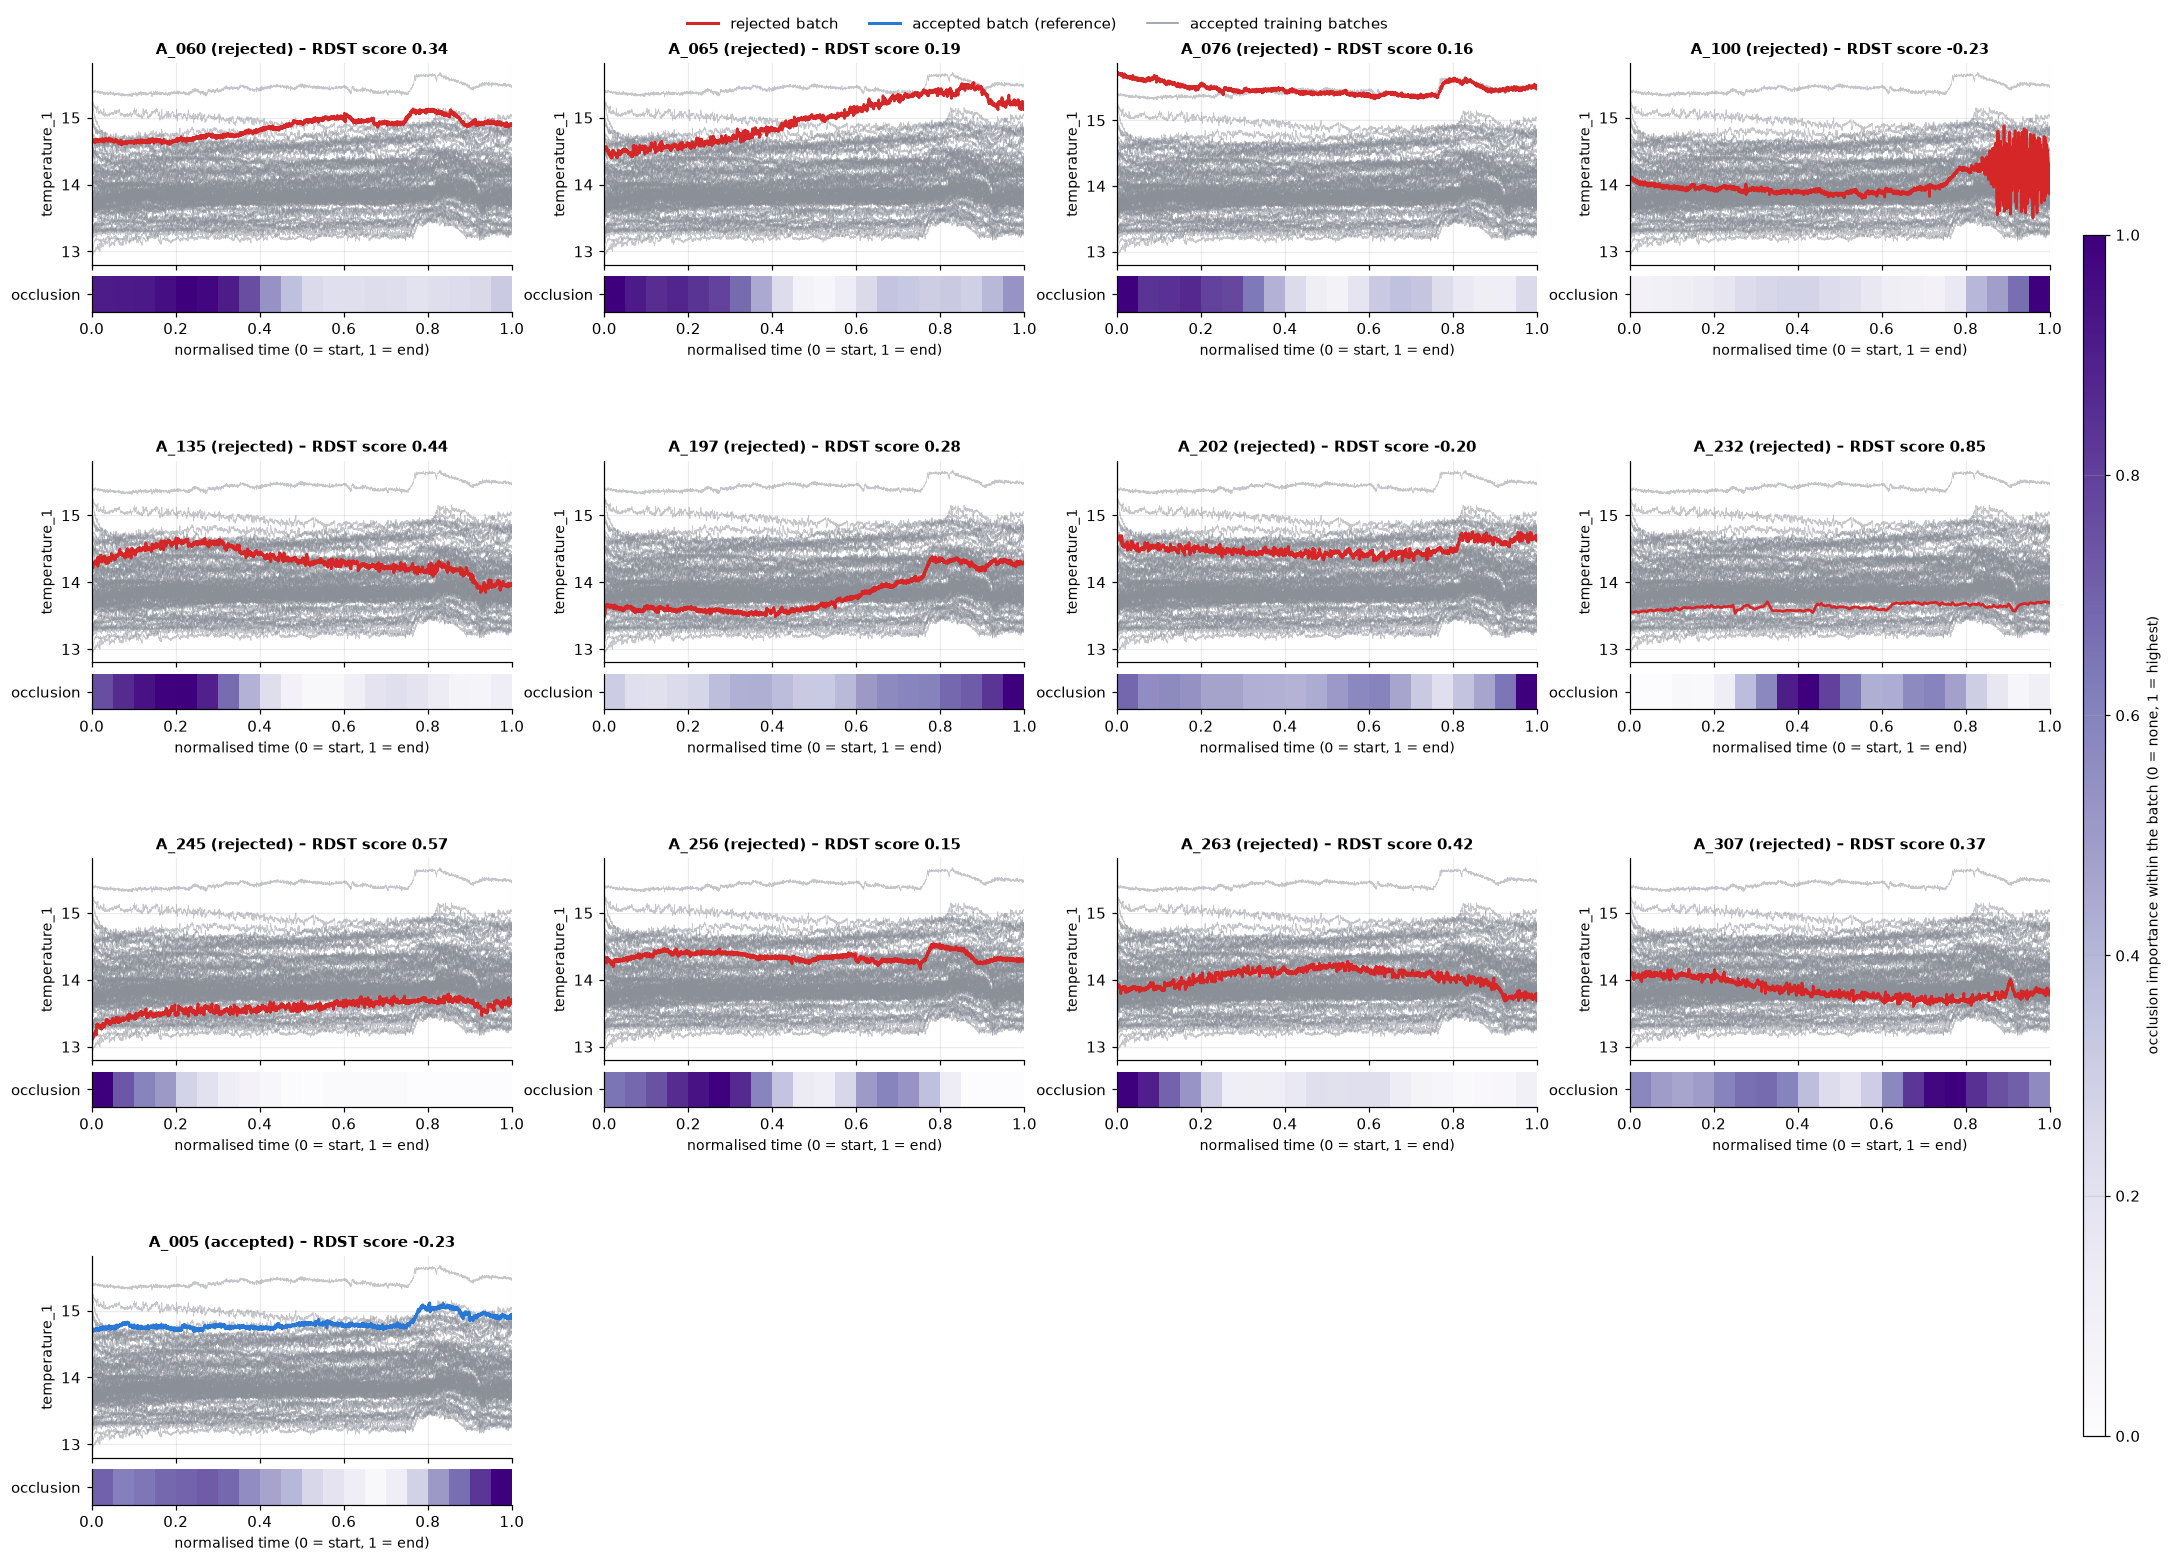

process A, rejected test batches – mean occlusion importance per 5 % slice:
[0.66 0.6  0.58 0.58 0.57 0.57 0.53 0.45 0.35 0.25 0.22 0.24 0.32 0.36
 0.36 0.31 0.3  0.28 0.31 0.41]


In [6]:
pA=[k[1] for k in EXPL if k[0]=="A"]; nr=int(np.ceil(len(pA)/4))
fig=plt.figure(figsize=(20,3.9*nr)); outer=fig.add_gridspec(nr,4,left=.04,right=.93,top=.95,hspace=.6,wspace=.22)
for k,b in enumerate(pA): block(fig,outer[k//4,k%4],"A",b,"temperature_1")
cax=fig.add_axes([.945,.15,.01,.7]); fig.colorbar(plt.cm.ScalarMappable(cmap="Purples",norm=plt.Normalize(0,1)),cax=cax,label="occlusion importance within the batch (0 = none, 1 = highest)")
fig.legend(handles=[Line2D([],[],color=REJ,lw=2,label="rejected batch"),Line2D([],[],color=TEST,lw=2,label="accepted batch (reference)"),Line2D([],[],color=ACC,lw=1,label="accepted training batches")],
           loc="lower center",bbox_to_anchor=(.47,.96),ncol=3,frameon=False,fontsize=10)
plt.show()
M=np.array([EXPL[("A",b)]["imp"] for b in pA if LAB["A"][b]=="rejected"])
print("process A, rejected test batches – mean occlusion importance per 5 % slice:"); print(np.round(M.mean(0),2))

## 3. Conclusions
**Detection on the same held-out batches (RDST test splits)**

| process | model | trained on | rejected caught | false alarms |
|---|---|---|---|---|
| A | RDST | accepted + rejected | **10 / 12 (83 %)** | 2 / 37 (5 %) |
| A | Robust deviation score | accepted only | 4 / 12 (33 %) | 4 / 37 (11 %) |
| A | Isolation Forest | accepted only | 0 / 12 (0 %) | 0 / 37 (0 %) |
| B | RDST | accepted + rejected | **2 / 2** | 0 / 18 |
| B | Robust deviation score | accepted only | **2 / 2** | 1 / 18 (6 %) |
| B | Isolation Forest | accepted only | 0 / 2 | 4 / 18 (22 %) |

- **Process A: RDST is far better** (83 % vs at most 33 %). Many rejected A batches look normal batch-by-batch; RDST can only find them because it has *seen* rejected batches and learnt their patterns. A one-class detector that knows only "normal" cannot learn what "rejected but normal-looking" means.
- **Process B: the simple robust score matches RDST** (both 2 / 2), because the fault – the aeration drop – makes rejected batches extremely unlike any accepted one. Isolation Forest fails on both processes, as in `anomaly_detection.ipynb`.
- One-class detectors remain useful for what RDST cannot do: flagging *new* kinds of faults that were never in the training data.
- Small test sets (12 and 2 rejected batches): the percentages are uncertain.

**Where RDST looks (occlusion)**
- **Process B:** for all 5 rejected batches the most important part of the run is the aeration drop (t = 500–1250); replacing that part by a normal trajectory lowers the RDST score by ≈ 1.6–1.9, enough to flip the verdict to "accepted" (scores were 0.77–1.0). RDST has learnt the right thing. (The importance share inside the window, ≈ 35 % vs 15 % by chance, is diluted because each occlusion hides 20 % of the run, so neighbouring slices share the credit.)
- **Process A:** the evidence is spread out and differs between batches – often the first third of the run (level offsets visible from the start, e.g. `A_060`, `A_065`, `A_076`, `A_245`, `A_263`), sometimes a specific episode such as the burst of `temperature_1` noise at the end of `A_100`. This matches the EDA: process A faults are mostly whole-run level/noise differences, not one time window.
- Unlike Grad-CAM on the autoencoder (`gradcam_anomaly.ipynb`), this model-agnostic explanation passes the process-B sanity check.